# IA-2: Research Paper-Based Implementation and Comparative Analysis of CNN Architectures for Real-World Applications

## Course
**Advanced Neural Network Architectures (2307411T)**

## Application Domain
 Plant Disease Classification**

## Problem Statement
Tomato plants are affected by several diseases that can significantly reduce crop yield and quality. Manual identification of tomato leaf diseases is time-consuming and depends on expert knowledge. Therefore, deep learning based image classification can be used to automatically identify tomato leaf diseases from leaf images.

## Research Paper
**Title:** A Lightweight Dual-Attention Network for Tomato Leaf Disease Identification

**Authors:** Enxu Zhang, Ning Zhang, Fei Li, Cheng Lv

**Journal:** Frontiers in Plant Science

**Publication Year:** 2024

**DOI:** 10.3389/fpls.2024.1420584

**Original Model:** LDAMNet (Lightweight Dual-Attention Network)



## Models Implemented

| Model | Category | Purpose |
|---|---|---|
| LDAMNet | Paper Baseline | Reproduce the architecture proposed in the selected research paper |
| ResNet50 | Conventional CNN | Additional reference CNN |
| EfficientNetV2-S | Efficient CNN | Compare accuracy with computational efficiency |
| ConvNeXt-Tiny | Modern CNN | Compare a modern CNN architecture with conventional CNNs |

## Dataset

The original research paper uses a large Plant Disease Classification Merged Dataset. Due to the large dataset size and practical limitations of Google Colab, this implementation uses a smaller publicly available tomato leaf disease dataset containing the same 10 target tomato disease/healthy categories.

**Important:** The experimental results obtained in this notebook represent results on the adapted dataset and should not be presented as an exact reproduction of the numerical results reported in the research paper.

## Experimental Workflow

Raw Dataset  
↓  
Dataset Inspection  
↓  
Data Preprocessing  
↓  
Train / Validation / Test Split  
↓  
Paper Baseline: LDAMNet  
↓  
Conventional CNN: ResNet50  
↓  
Efficient CNN: EfficientNetV2-S  
↓  
Modern CNN: ConvNeXt-Tiny  
↓  
Training and Validation  
↓  
Performance Evaluation  
↓  
Confusion Matrix / ROC-AUC  
↓  
Computational Comparison  
↓  
Final Analysis and Conclusion

### Dataset source

The Hugging Face dataset `Project-AgML/tomato_leaf_disease` contains 11,000 images across exactly 10 tomato classes, with 1,100 images per class. The dataset page reports a total size of about 187 MB.

Source: https://huggingface.co/datasets/Project-AgML/tomato_leaf_disease

In [ ]:
# 1. Install libraries

!pip -q install datasets scikit-learn seaborn

import os
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from datasets import load_dataset

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Libraries installed.")

Libraries installed.


In [ ]:
# 2. Download the SMALL dataset directly from Hugging Face
# No Kaggle authentication required.

dataset = load_dataset(
    "Project-AgML/tomato_leaf_disease"
)

print(dataset)
print("Training rows:", len(dataset["train"]))

README.md:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/11000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 11000
    })
})
Training rows: 11000


In [ ]:
# 3. Inspect dataset

raw_train = dataset["train"]

print("Columns:", raw_train.column_names)
print("Number of images:", len(raw_train))

print("\nFeatures:")
print(raw_train.features)

# Show label names
label_feature = raw_train.features["label"]
CLASS_NAMES = label_feature.names
NUM_CLASSES = len(CLASS_NAMES)

print("\nNumber of classes:", NUM_CLASSES)

for i, name in enumerate(CLASS_NAMES):
    print(i, name)

Columns: ['image', 'label']
Number of images: 11000

Features:
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['Bacterial Spot', 'Early Blight', 'Healthy', 'Late Blight', 'Leaf Mold', 'Septoria Leaf Spot', 'Spider Mites Two-spotted Spider Mite', 'Target Spot', 'Tomato Mosaic Virus', 'Tomato Yellow Leaf Curl Virus'])}

Number of classes: 10
0 Bacterial Spot
1 Early Blight
2 Healthy
3 Late Blight
4 Leaf Mold
5 Septoria Leaf Spot
6 Spider Mites Two-spotted Spider Mite
7 Target Spot
8 Tomato Mosaic Virus
9 Tomato Yellow Leaf Curl Virus


,Class,Images
0,Bacterial Spot,1100
1,Early Blight,1100
2,Healthy,1100
3,Late Blight,1100
4,Leaf Mold,1100
5,Septoria Leaf Spot,1100
6,Spider Mites Two-spotted Spider Mite,1100
7,Target Spot,1100
8,Tomato Mosaic Virus,1100
9,Tomato Yellow Leaf Curl Virus,1100


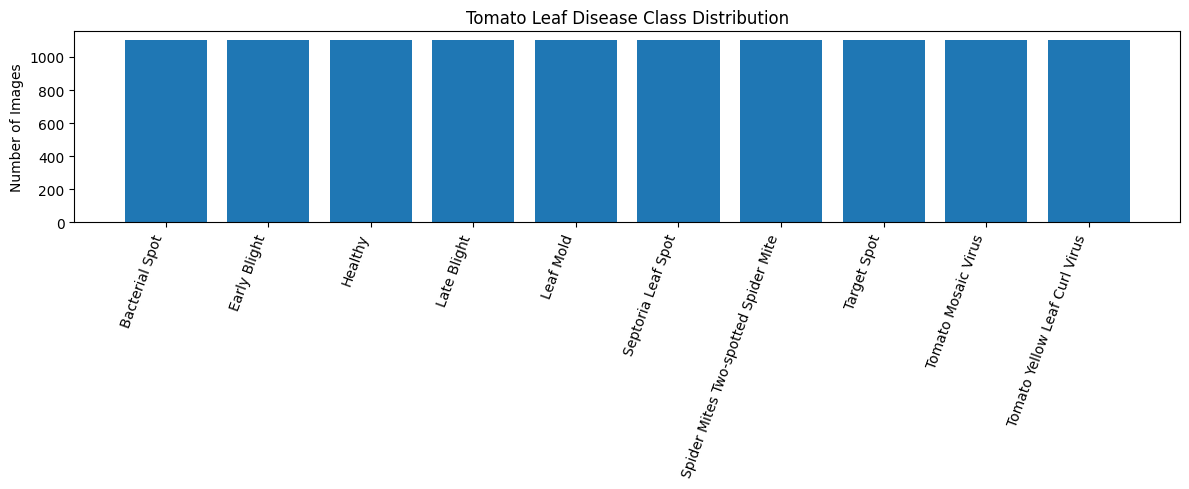

In [ ]:
# 4. Class distribution

labels = np.array(raw_train["label"])

counts = np.bincount(labels, minlength=NUM_CLASSES)

distribution_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Images": counts
})

display(distribution_df)

plt.figure(figsize=(12, 5))
plt.bar(CLASS_NAMES, counts)
plt.xticks(rotation=70, ha="right")
plt.ylabel("Number of Images")
plt.title("Tomato Leaf Disease Class Distribution")
plt.tight_layout()
plt.show()

In [ ]:
# 5. Reproducibility and configuration

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 1e-4
NUM_WORKERS = 2

print("Device:", DEVICE)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

Device: cuda
Image size: 224
Batch size: 32
Epochs: 10


## 6. Train / validation / test split

The online dataset provides one training split. We create a **70/15/15 stratified split** so all four CNN models are evaluated on the same data.


In [ ]:
# 6. Stratified 70/15/15 split

all_indices = np.arange(len(raw_train))
all_labels = np.array(raw_train["label"])

from sklearn.model_selection import train_test_split

train_idx, temp_idx = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=all_labels
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=all_labels[temp_idx]
)

train_hf = raw_train.select(train_idx.tolist())
val_hf = raw_train.select(val_idx.tolist())
test_hf = raw_train.select(test_idx.tolist())

print("Train:", len(train_hf))
print("Validation:", len(val_hf))
print("Test:", len(test_hf))

Train: 7700
Validation: 1650
Test: 1650


In [ ]:
# 7. Image preprocessing

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])


class HFDataset(Dataset):
    def __init__(self, hf_dataset, transform=None):
        self.dataset = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]
        image = item["image"].convert("RGB")
        label = int(item["label"])

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = HFDataset(train_hf, train_transform)
val_dataset = HFDataset(val_hf, eval_transform)
test_dataset = HFDataset(test_hf, eval_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("DataLoaders ready.")

DataLoaders ready.


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


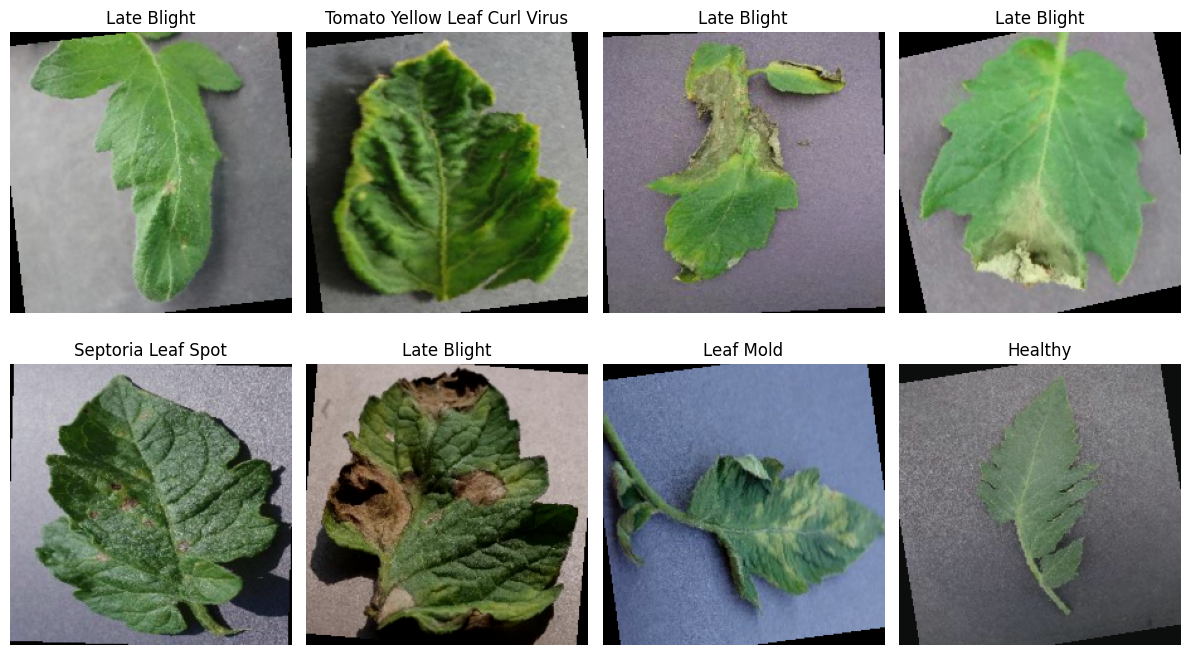

In [ ]:
# 8. Display sample images

images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 7))

for i in range(min(8, len(images))):
    img = images[i].permute(1, 2, 0).numpy()
    img = img * np.array([0.229, 0.224, 0.225])
    img = img + np.array([0.485, 0.456, 0.406])
    img = np.clip(img, 0, 1)

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(CLASS_NAMES[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

# 9. Model 1 — Paper-inspired LDAMNet

The selected paper proposes a lightweight dual-attention network (LDAMNet). This implementation is **paper-inspired** with lightweight convolutional blocks and channel/spatial attention.

In [ ]:
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        hidden = max(channels // reduction, 4)

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.fc = nn.Sequential(
            nn.Conv2d(channels, hidden, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return x * self.fc(self.pool(x))


class SpatialAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, 7, padding=3)

    def forward(self, x):
        avg = torch.mean(x, dim=1, keepdim=True)
        mx, _ = torch.max(x, dim=1, keepdim=True)

        attention = torch.sigmoid(
            self.conv(torch.cat([avg, mx], dim=1))
        )

        return x * attention


class DACBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch)
        )

        self.ca = ChannelAttention(out_ch)
        self.sa = SpatialAttention()

    def forward(self, x):
        x = self.conv(x)
        x = self.ca(x)
        x = self.sa(x)
        return torch.relu(x)


class LDAMNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        self.stage1 = DACBlock(32, 32)
        self.down1 = nn.MaxPool2d(2)

        self.stage2 = DACBlock(32, 64)
        self.down2 = nn.MaxPool2d(2)

        self.stage3 = nn.Sequential(
            DACBlock(64, 128),
            DACBlock(128, 128)
        )

        self.down3 = nn.MaxPool2d(2)

        self.stage4 = DACBlock(128, 256)

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.down1(x)

        x = self.stage2(x)
        x = self.down2(x)

        x = self.stage3(x)
        x = self.down3(x)

        x = self.stage4(x)

        x = self.pool(x)
        x = x.flatten(1)

        return self.fc(x)


def build_ldamnet():
    return LDAMNet(NUM_CLASSES)

# 10. Model 2 — ResNet50

In [ ]:
def build_resnet50():
    model = models.resnet50(
        weights=models.ResNet50_Weights.DEFAULT
    )

    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    return model

# 11. Model 3 — EfficientNetV2-S

In [ ]:
def build_efficientnet():
    model = models.efficientnet_v2_s(
        weights=models.EfficientNet_V2_S_Weights.DEFAULT
    )

    model.classifier[1] = nn.Linear(
        model.classifier[1].in_features,
        NUM_CLASSES
    )

    return model

# 12. Model 4 — ConvNeXt-Tiny

In [ ]:
def build_convnext():
    model = models.convnext_tiny(
        weights=models.ConvNeXt_Tiny_Weights.DEFAULT
    )

    model.classifier[2] = nn.Linear(
        model.classifier[2].in_features,
        NUM_CLASSES
    )

    return model

In [ ]:
# 13. Model parameter counts

MODEL_BUILDERS = {
    "LDAMNet": build_ldamnet,
    "ResNet50": build_resnet50,
    "EfficientNetV2-S": build_efficientnet,
    "ConvNeXt-Tiny": build_convnext
}


def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


for name, builder in MODEL_BUILDERS.items():

    model = builder()

    print(
        f"{name:20s}: "
        f"{count_parameters(model):,} parameters"
    )

    del model

LDAMNet             : 1,507,525 parameters
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 203MB/s]


ResNet50            : 23,528,522 parameters
Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 165MB/s]


EfficientNetV2-S    : 20,190,298 parameters
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 192MB/s] 


ConvNeXt-Tiny       : 27,827,818 parameters


# 14. Training and evaluation

In [ ]:
criterion = nn.CrossEntropyLoss()


def train_model(model, model_name):

    model = model.to(DEVICE)

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_state = copy.deepcopy(model.state_dict())
    best_val_acc = 0.0

    start_time = time.time()

    for epoch in range(EPOCHS):

        # -----------------
        # Training
        # -----------------

        model.train()

        total_loss = 0
        correct = 0
        total = 0

        for x, y in train_loader:

            x = x.to(DEVICE)
            y = y.to(DEVICE)

            optimizer.zero_grad()

            output = model(x)
            loss = criterion(output, y)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * x.size(0)

            correct += (
                output.argmax(1) == y
            ).sum().item()

            total += y.size(0)

        train_loss = total_loss / total
        train_acc = correct / total

        # -----------------
        # Validation
        # -----------------

        model.eval()

        val_loss_total = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for x, y in val_loader:

                x = x.to(DEVICE)
                y = y.to(DEVICE)

                output = model(x)
                loss = criterion(output, y)

                val_loss_total += (
                    loss.item() * x.size(0)
                )

                val_correct += (
                    output.argmax(1) == y
                ).sum().item()

                val_total += y.size(0)

        val_loss = val_loss_total / val_total
        val_acc = val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(
                model.state_dict()
            )

        print(
            f"{model_name} | "
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

    training_time = time.time() - start_time

    model.load_state_dict(best_state)

    return model, history, training_time

In [ ]:
def evaluate_model(model):

    model.eval()

    y_true = []
    y_pred = []
    y_prob = []

    with torch.no_grad():

        for x, y in test_loader:

            x = x.to(DEVICE)

            output = model(x)

            probabilities = torch.softmax(
                output,
                dim=1
            )

            y_true.extend(y.numpy())

            y_pred.extend(
                output.argmax(1)
                .cpu()
                .numpy()
            )

            y_prob.extend(
                probabilities
                .cpu()
                .numpy()
            )

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_prob = np.array(y_prob)

    metrics = {
        "Accuracy": accuracy_score(
            y_true, y_pred
        ),

        "Precision": precision_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "Recall": recall_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "F1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    }

    try:
        metrics["AUC"] = roc_auc_score(
            y_true,
            y_prob,
            multi_class="ovr",
            average="weighted"
        )
    except:
        metrics["AUC"] = np.nan

    return metrics, y_true, y_pred, y_prob

# 15. Train all four models

For a quick test, `EPOCHS = 10`.

If you have enough Colab GPU time, you can change it to 20–30 for your final IA-2 run.

In [ ]:
trained_models = {}
histories = {}
results = []

for model_name, builder in MODEL_BUILDERS.items():

    print("\n" + "=" * 70)
    print("TRAINING:", model_name)
    print("=" * 70)

    model = builder()

    params = count_parameters(model)

    model, history, training_time = train_model(
        model,
        model_name
    )

    metrics, y_true, y_pred, y_prob = evaluate_model(
        model
    )

    trained_models[model_name] = model
    histories[model_name] = history

    results.append({
        "Model": model_name,
        "Parameters": params,
        "Accuracy": metrics["Accuracy"],
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall"],
        "F1": metrics["F1"],
        "AUC": metrics["AUC"],
        "Training Time (s)": training_time
    })

    torch.save(
        model.state_dict(),
        f"{model_name.replace('-', '_')}.pth"
    )

    print("\nTest metrics:")

    for key, value in metrics.items():
        print(f"{key}: {value:.4f}")

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


TRAINING: LDAMNet
LDAMNet | Epoch 1/10 | Train Acc: 0.6029 | Val Acc: 0.8267
LDAMNet | Epoch 2/10 | Train Acc: 0.7761 | Val Acc: 0.7588
LDAMNet | Epoch 3/10 | Train Acc: 0.8235 | Val Acc: 0.8364
LDAMNet | Epoch 4/10 | Train Acc: 0.8631 | Val Acc: 0.8812
LDAMNet | Epoch 5/10 | Train Acc: 0.8848 | Val Acc: 0.9352
LDAMNet | Epoch 6/10 | Train Acc: 0.8957 | Val Acc: 0.9521
LDAMNet | Epoch 7/10 | Train Acc: 0.9082 | Val Acc: 0.9224
LDAMNet | Epoch 8/10 | Train Acc: 0.9169 | Val Acc: 0.9539
LDAMNet | Epoch 9/10 | Train Acc: 0.9258 | Val Acc: 0.9600
LDAMNet | Epoch 10/10 | Train Acc: 0.9290 | Val Acc: 0.9667

Test metrics:
Accuracy: 0.9545
Precision: 0.9550
Recall: 0.9545
F1: 0.9543
AUC: 0.9988

TRAINING: ResNet50
ResNet50 | Epoch 1/10 | Train Acc: 0.8445 | Val Acc: 0.9679
ResNet50 | Epoch 2/10 | Train Acc: 0.9696 | Val Acc: 0.9903
ResNet50 | Epoch 3/10 | Train Acc: 0.9845 | Val Acc: 0.9903
ResNet50 | Epoch 4/10 | Train Acc: 0.9856 | Val Acc: 0.9903
ResNet50 | Epoch 5/10 | Train Acc: 0.9917 

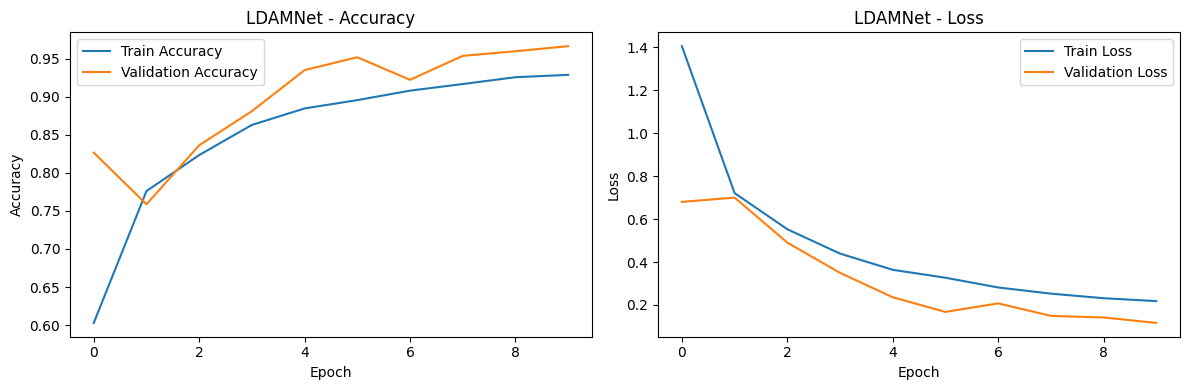

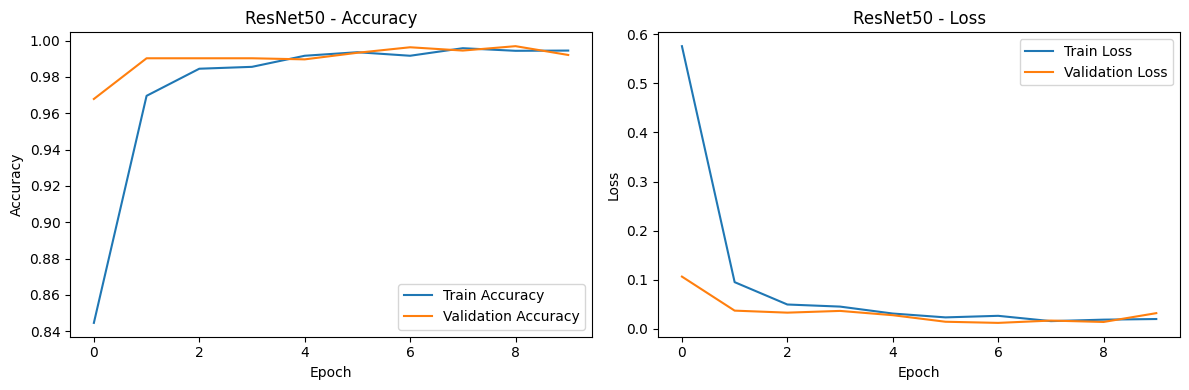

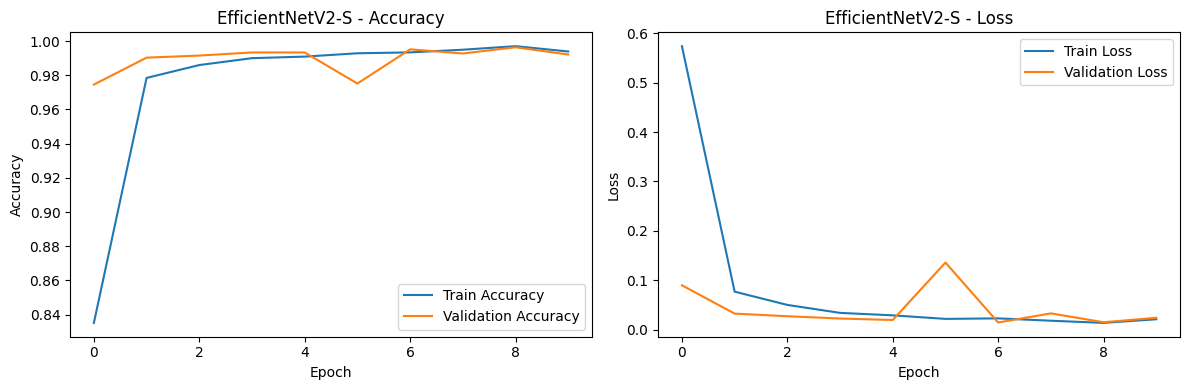

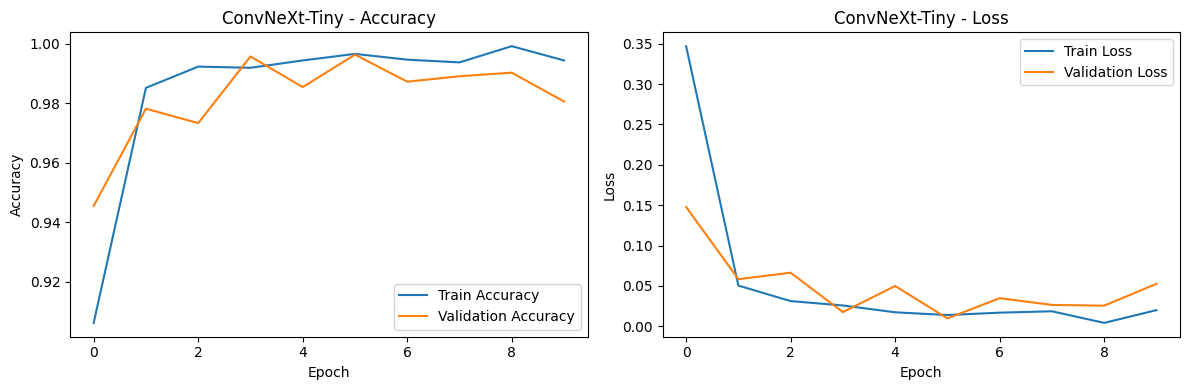

In [ ]:
# 16. Training graphs

for model_name, history in histories.items():

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)

    plt.plot(
        history["train_acc"],
        label="Train Accuracy"
    )

    plt.plot(
        history["val_acc"],
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(model_name + " - Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)

    plt.plot(
        history["train_loss"],
        label="Train Loss"
    )

    plt.plot(
        history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(model_name + " - Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

In [ ]:
# 17. Final comparison table

comparison_df = pd.DataFrame(results)

comparison_df["Parameters (M)"] = (
    comparison_df["Parameters"] / 1_000_000
).round(2)

for col in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "AUC"
]:
    comparison_df[col] = comparison_df[col].round(4)

comparison_df = comparison_df[
    [
        "Model",
        "Parameters (M)",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "AUC",
        "Training Time (s)"
    ]
]

display(comparison_df)

comparison_df.to_csv(
    "/content/IA2_Tomato_CNN_Comparison.csv",
    index=False
)

print(
    "Saved: /content/IA2_Tomato_CNN_Comparison.csv"
)

,Model,Parameters (M),Accuracy,Precision,Recall,F1,AUC,Training Time (s)
0,LDAMNet,1.51,0.9545,0.9550,0.9545,0.9543,0.9988,455.170900
1,ResNet50,23.53,0.9921,0.9922,0.9921,0.9921,0.9992,805.113418
2,EfficientNetV2-S,20.19,0.9952,0.9952,0.9952,0.9952,0.9994,908.828661
3,ConvNeXt-Tiny,27.83,0.9970,0.9970,0.9970,0.9970,0.9999,1339.832080


Saved: /content/IA2_Tomato_CNN_Comparison.csv


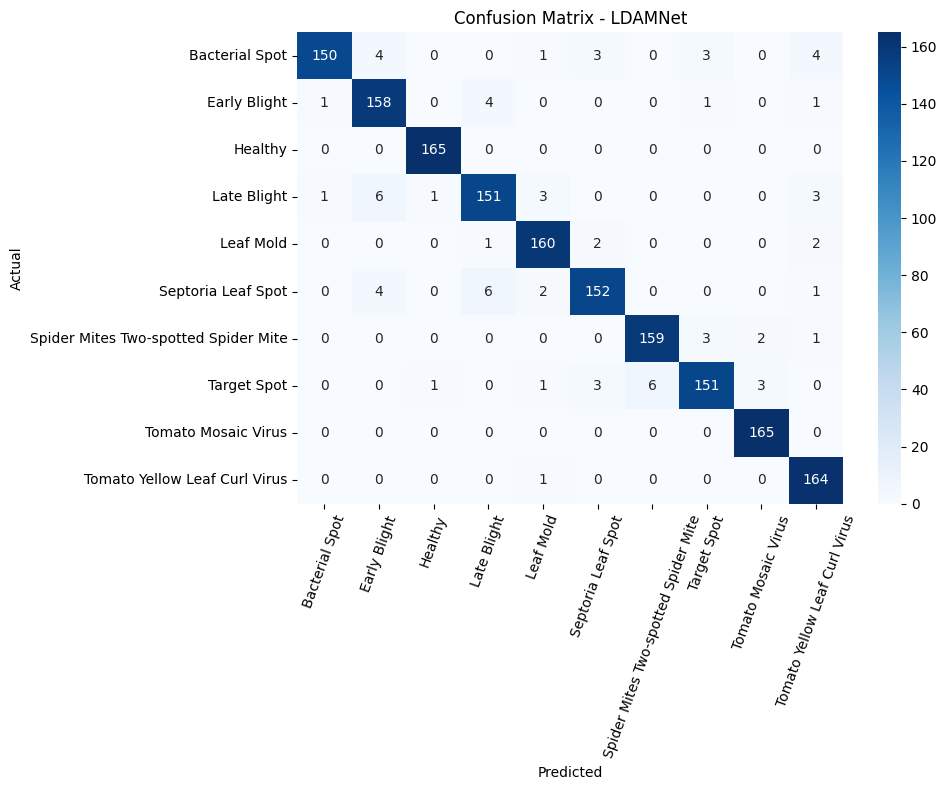

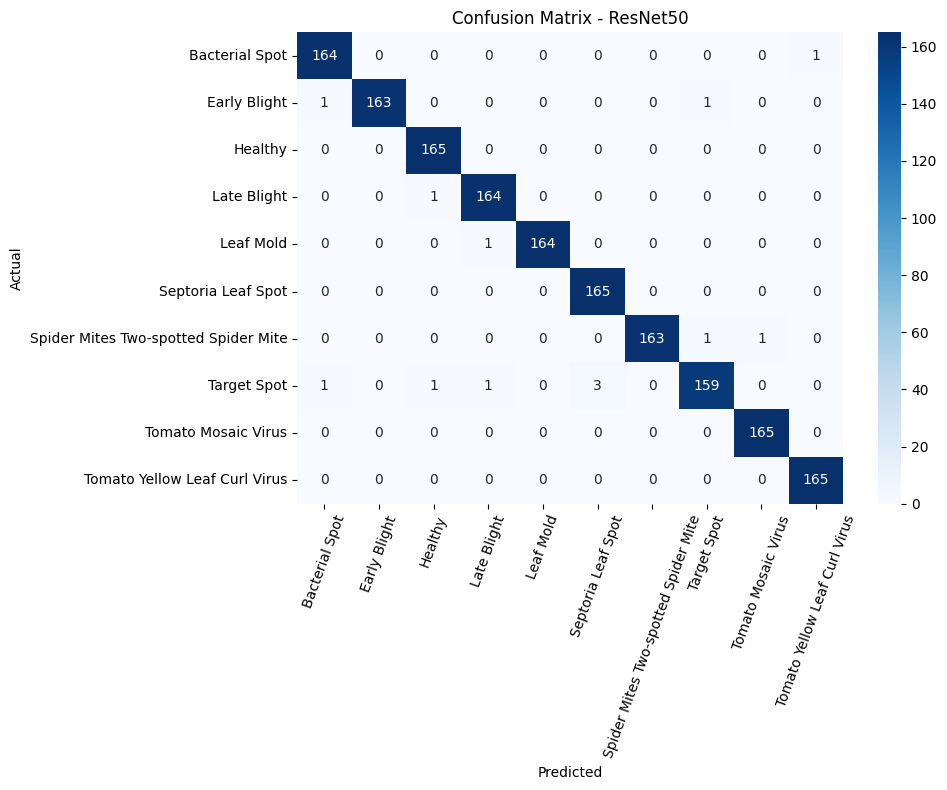

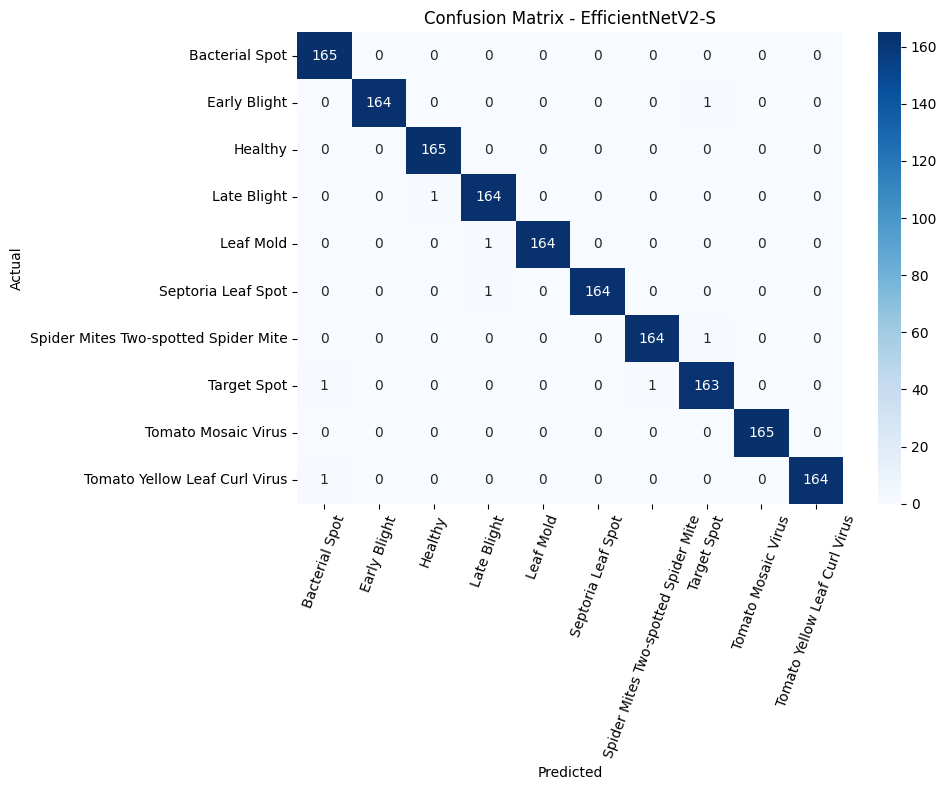

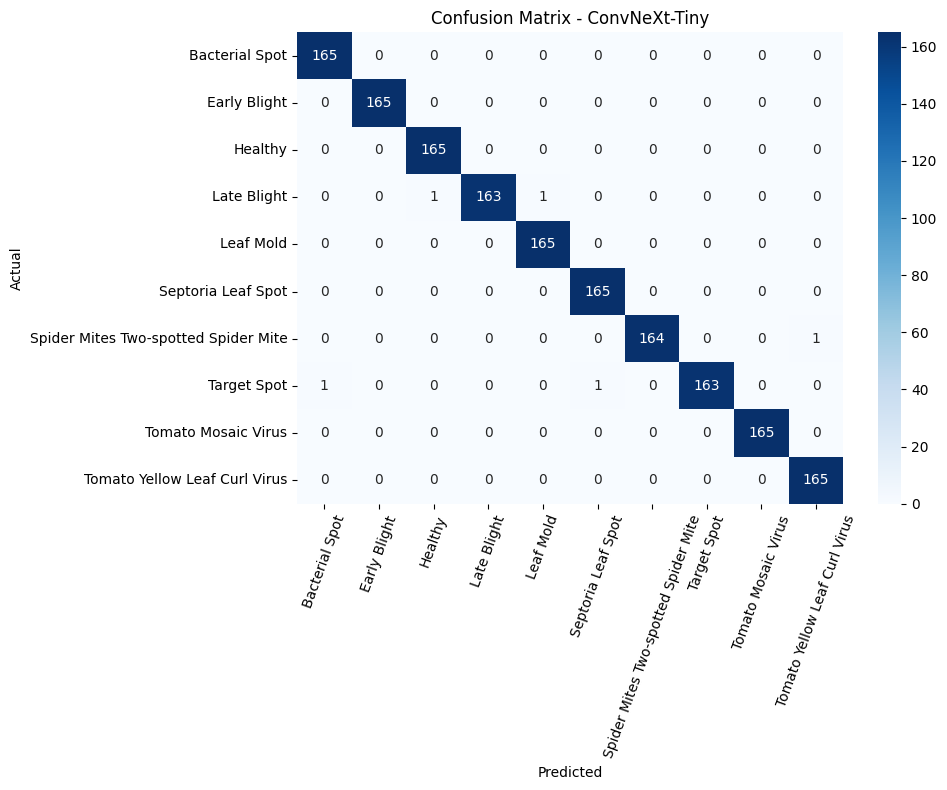

In [ ]:
# 18. Confusion matrices

for model_name, model in trained_models.items():

    _, y_true, y_pred, _ = evaluate_model(model)

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    plt.figure(figsize=(10, 8))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(
        "Confusion Matrix - " + model_name
    )

    plt.xticks(rotation=70)
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

In [ ]:
# 19. Classification reports

for model_name, model in trained_models.items():

    _, y_true, y_pred, _ = evaluate_model(model)

    print("\n" + "=" * 80)
    print(model_name)
    print("=" * 80)

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=CLASS_NAMES,
            zero_division=0
        )
    )


LDAMNet
                                      precision    recall  f1-score   support

                      Bacterial Spot       0.99      0.91      0.95       165
                        Early Blight       0.92      0.96      0.94       165
                             Healthy       0.99      1.00      0.99       165
                         Late Blight       0.93      0.92      0.92       165
                           Leaf Mold       0.95      0.97      0.96       165
                  Septoria Leaf Spot       0.95      0.92      0.94       165
Spider Mites Two-spotted Spider Mite       0.96      0.96      0.96       165
                         Target Spot       0.96      0.92      0.93       165
                 Tomato Mosaic Virus       0.97      1.00      0.99       165
       Tomato Yellow Leaf Curl Virus       0.93      0.99      0.96       165

                            accuracy                           0.95      1650
                           macro avg       0.95      